# 06 — Testing & Validation

Inline sanity tests for every stage of the pipeline (data tables, hyperedge/incidence construction, sparse ops, model shapes & gradients), plus validation of the trained model from notebook 04 (loss/metric improvement, confusion matrix, lineage-coherence).

Each check prints `PASS`/`FAIL`; a final summary tallies the results.

In [1]:
import os
import sys

import matplotlib.pyplot as plt
import pandas as pd
import torch
from sklearn.metrics import confusion_matrix, roc_auc_score

sys.path.insert(0, os.path.abspath('..'))

from dhgnn_lib.cell_universe import CellUniverse
from dhgnn_lib import hyperedges, incidence, labels, node_features, sparse_ops, training
from dhgnn_lib.dhgnn_model import DHGNNModel
from dhgnn_lib.hypersagnn import HyperSAGNNLayer
from dhgnn_lib.incidence import HyperedgeBatch

RAW_DIR = '../raw_dataset'
OUTPUT_DIR = '../output_tables'
CKPT_DIR = '../checkpoints'

passed, failed = [], []


def check(name, cond):
    (passed if cond else failed).append(name)
    print(('PASS - ' if cond else 'FAIL - ') + name)


## 1. Data pipeline checks

In [2]:
universe = CellUniverse.build(RAW_DIR, OUTPUT_DIR)
check('cell universe is non-empty with unique names', len(universe) == len(set(universe.names)) and len(universe) > 0)
check('cell universe size in expected range [1000, 2000]', 1000 <= len(universe) <= 2000)

lineage_df = pd.read_csv(os.path.join(OUTPUT_DIR, 'lineage_lookup_table.csv'))
check('lineage_lookup_table.csv has 642 rows', len(lineage_df) == 642)
check('every lineage hyperedge has 3 members', (lineage_df['members'].str.count(r'\|') == 2).all())

spatial_df = pd.read_csv(os.path.join(OUTPUT_DIR, 'spatial_lookup_table.csv'))
check('spatial_lookup_table.csv is non-empty', len(spatial_df) > 0)
check('every spatial cluster has >= min_samples members', (spatial_df['cluster_size'] >= hyperedges.SPATIAL_MIN_SAMPLES).all())

functional_df = pd.read_csv(os.path.join(OUTPUT_DIR, 'functional_lookup_table.csv'))
check('functional_lookup_table.csv has 4436 rows', len(functional_df) == 4436)

PASS - cell universe is non-empty with unique names
PASS - cell universe size in expected range [1000, 2000]
PASS - lineage_lookup_table.csv has 642 rows
PASS - every lineage hyperedge has 3 members
PASS - spatial_lookup_table.csv is non-empty
PASS - every spatial cluster has >= min_samples members
PASS - functional_lookup_table.csv has 4436 rows


In [3]:
nfb = node_features.NodeFeatureBuilder(RAW_DIR, universe)
x = nfb.build(100)
check('node feature matrix has shape (N, 10)', tuple(x.shape) == (len(universe), 10))
check('node features contain no NaNs', not torch.isnan(x).any().item())
check('presence flags are binary', set(x[:, 5].unique().tolist()).issubset({0.0, 1.0}))

PASS - node feature matrix has shape (N, 10)
PASS - node features contain no NaNs
PASS - presence flags are binary


## 2. Hyperedge & incidence (`H_aug(t)`) checks

In [4]:
store = hyperedges.HyperedgeStore(RAW_DIR, OUTPUT_DIR, universe)
lin_set, func_set = store.lineage(), store.functional()
check('lineage hyperedge set has 642 edges', lin_set.num_edges == 642)
check('functional hyperedge set has 4436 edges', func_set.num_edges == 4436)

T_SAMPLE = 100
spatial = store.spatial(T_SAMPLE)
batch = incidence.assemble(len(universe), spatial, lin_set, func_set)

check(
    'H_aug(t) edge count equals sum of the 3 components',
    batch.num_edges == spatial.num_edges + lin_set.num_edges + func_set.num_edges,
)
sizes = batch.edge_sizes()
check('every hyperedge has >= 2 member cells', bool((sizes >= 2).all()))
check(
    'cell_index values are valid node indices',
    bool((batch.cell_index >= 0).all()) and bool((batch.cell_index < batch.num_nodes).all()),
)

PASS - lineage hyperedge set has 642 edges
PASS - functional hyperedge set has 4436 edges
PASS - H_aug(t) edge count equals sum of the 3 components
PASS - every hyperedge has >= 2 member cells
PASS - cell_index values are valid node indices


## 3. Sparse-op checks (`dhgnn_lib.sparse_ops`)

In [5]:
src = torch.tensor([1.0, 2.0, 3.0, 4.0])
index = torch.tensor([0, 0, 1, 1])

check('scatter_sum matches manual sums', torch.allclose(sparse_ops.scatter_sum(src, index, 2), torch.tensor([3.0, 7.0])))
check('scatter_mean matches manual means', torch.allclose(sparse_ops.scatter_mean(src, index, 2), torch.tensor([1.5, 3.5])))
check('scatter_max matches manual maxes', torch.allclose(sparse_ops.scatter_max(src, index, 2), torch.tensor([2.0, 4.0])))

soft = sparse_ops.scatter_softmax(src, index, 2)
check('scatter_softmax sums to 1 within each group', torch.allclose(sparse_ops.scatter_sum(soft, index, 2), torch.ones(2)))


PASS - scatter_sum matches manual sums
PASS - scatter_mean matches manual means
PASS - scatter_max matches manual maxes
PASS - scatter_softmax sums to 1 within each group


## 4. Model checks: shapes, gradients, and the in-place-autograd regression test

In [6]:
torch.manual_seed(0)
N_TOY, D_TOY = 10, 8
cell_index = torch.tensor([0, 1, 2, 2, 3, 4, 4, 5, 6, 7])
edge_index = torch.tensor([0, 0, 0, 1, 1, 1, 2, 2, 2, 2])
edge_type = torch.tensor([0, 1, 2])
edge_weight = torch.ones(3)
toy_batch = HyperedgeBatch(cell_index, edge_index, edge_type, edge_weight, N_TOY, 3)

h = torch.randn(N_TOY, D_TOY, requires_grad=True)
layer = HyperSAGNNLayer(D_TOY)
out = layer(h, toy_batch)
check('HyperSAGNNLayer preserves (N, D) shape', tuple(out.shape) == (N_TOY, D_TOY))

out.sum().backward()
check('gradients flow back to input embeddings', h.grad is not None and not torch.isnan(h.grad).any().item())


PASS - HyperSAGNNLayer preserves (N, D) shape
PASS - gradients flow back to input embeddings


In [7]:
# Regression test: repeated forward/backward must not trigger the in-place
# autograd error from scatter_reduce_ + boolean-mask assignment.
h2 = torch.randn(N_TOY, D_TOY, requires_grad=True)
layer2 = HyperSAGNNLayer(D_TOY)
opt2 = torch.optim.AdamW(layer2.parameters(), lr=1e-3)

ok = True
try:
    for _ in range(2):
        out2 = layer2(h2, toy_batch)
        opt2.zero_grad()
        out2.sum().backward()
        opt2.step()
except RuntimeError as exc:
    ok = False
    print('RuntimeError:', exc)

check('repeated forward/backward does not raise an in-place autograd error', ok)


PASS - repeated forward/backward does not raise an in-place autograd error


In [8]:
model_toy = DHGNNModel(num_features=6, hidden_dim=16, num_layers=2)
x_toy = torch.randn(N_TOY, 6)
out_toy = model_toy(x_toy, toy_batch)

check('fate_logits shape == (N, len(FATE_NAMES))', tuple(out_toy['fate_logits'].shape) == (N_TOY, len(labels.FATE_NAMES)))
check('embeddings shape == (N, hidden_dim)', tuple(out_toy['embeddings'].shape) == (N_TOY, 16))

PASS - fate_logits shape == (N, len(FATE_NAMES))
PASS - embeddings shape == (N, hidden_dim)


## 5. Validation of the trained model (checkpoint from notebook 04)

In [9]:
import json as _json
meta = _json.load(open(os.path.join(CKPT_DIR, 'model_meta.json')))
model = DHGNNModel(num_features=meta['num_features'], hidden_dim=meta['hidden_dim'], num_layers=meta['num_layers'])
model.load_state_dict(torch.load(os.path.join(CKPT_DIR, 'dhgnn_model.pt')))
model.eval()

print(f"val fate loss: {meta['val_loss_first']:.4f} -> {meta['val_loss_best']:.4f}")
print(f"val fate acc:  {meta['fate_acc_first']:.4f} -> {meta['fate_acc']:.4f}")
check('validation fate loss improved with training', meta['val_loss_best'] < meta['val_loss_first'])
check('validation fate accuracy improved with training', meta['fate_acc'] >= meta['fate_acc_first'])

val fate loss: 0.2188 -> 0.0875
val fate acc:  0.8947 -> 0.9581
PASS - validation fate loss improved with training
PASS - validation fate accuracy improved with training


### Fate confusion matrix at the final timepoint

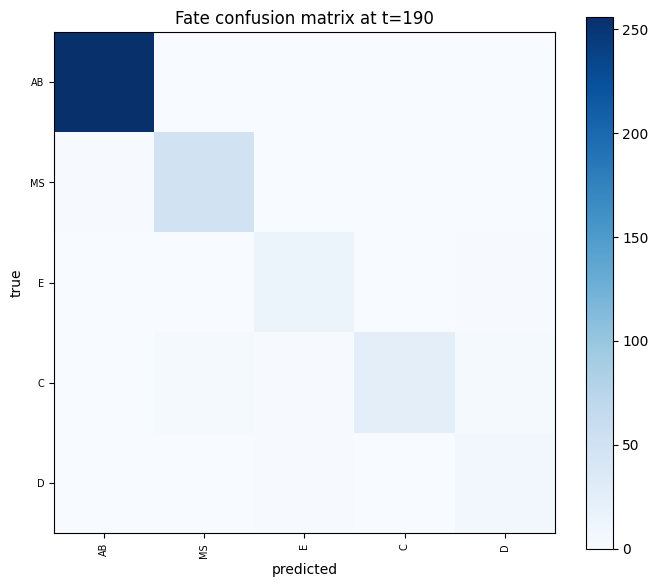

In [10]:
fate = labels.fate_labels(universe)

tps = store.timepoints
t_val = tps[-1]
batch_t = incidence.assemble(len(universe), store.spatial(t_val), store.lineage(), store.functional())
x_t = nfb.build(t_val)
present = x_t[:, 5].bool()
static_sets = {'lineage': store.lineage(), 'functional': store.functional()}

with torch.no_grad():
    out = model(x_t, batch_t, universe=universe, present_mask=present, static_sets=static_sets, recluster=True)

fate_true = fate[present].numpy()
fate_pred = out['fate_logits'][present].argmax(-1).numpy()
present_classes = sorted(set(fate_true.tolist()) | set(fate_pred.tolist()))
cm = confusion_matrix(fate_true, fate_pred, labels=present_classes)

fig, ax = plt.subplots(figsize=(7, 6))
im = ax.imshow(cm, cmap='Blues')
ax.set_xticks(range(len(present_classes)))
ax.set_xticklabels([labels.FATE_NAMES[c] for c in present_classes], rotation=90, fontsize=7)
ax.set_yticks(range(len(present_classes)))
ax.set_yticklabels([labels.FATE_NAMES[c] for c in present_classes], fontsize=7)
ax.set_xlabel('predicted'); ax.set_ylabel('true')
ax.set_title(f'Fate confusion matrix at t={t_val}')
fig.colorbar(im, ax=ax)
fig.tight_layout()
plt.show()

### Lineage-coherence (representation quality)

Do same-lineage cells cluster together in the learned embedding space? A clean, non-leaky check of representation quality (lineage comes from the cell name, never a target). Compared against the raw input features as a baseline.

In [11]:
from dhgnn_lib import metrics
import numpy as _np

emb_all = out['embeddings'][present].detach().numpy()
raw_all = x_t[present].numpy()
y_all = fate[present].numpy()
unk = labels.FATE_NAMES.index('unknown')
keep = _np.array([c != unk for c in y_all])
yk, embk, rawk = y_all[keep], emb_all[keep], raw_all[keep]
vc = {c: int((yk == c).sum()) for c in _np.unique(yk)}
good = _np.array([vc[c] >= 5 for c in yk])
yg, embg, rawg = yk[good], embk[good], rawk[good]

emb_sil, emb_knn = metrics.lineage_coherence(embg, yg)
raw_sil, raw_knn = metrics.lineage_coherence(rawg, yg)
print(f'lineage-coherence @ t={t_val}  (n={len(yg)} founder cells)')
print(f'  learned embeddings: silhouette={emb_sil:+.3f}  kNN-purity={emb_knn:.3f}')
print(f'  raw features      : silhouette={raw_sil:+.3f}  kNN-purity={raw_knn:.3f}')
check('embedding lineage silhouette is positive (cells cluster by lineage)', emb_sil > 0)
check('embeddings beat raw features on lineage kNN-purity', emb_knn > raw_knn)

lineage-coherence @ t=190  (n=360 founder cells)
  learned embeddings: silhouette=+0.683  kNN-purity=0.977
  raw features      : silhouette=-0.151  kNN-purity=0.721
PASS - embedding lineage silhouette is positive (cells cluster by lineage)
PASS - embeddings beat raw features on lineage kNN-purity


## Summary

In [12]:
print('=' * 60)
print(f'TESTS PASSED: {len(passed)} / {len(passed) + len(failed)}')
if failed:
    print('FAILED CHECKS:')
    for f in failed:
        print('  -', f)
print('=' * 60)


TESTS PASSED: 28 / 28


## Project status

The pipeline is implemented end-to-end as Jupyter notebooks backed by the `dhgnn_lib` package:

- **Lookup tables**: `functional_lookup_table.csv`, `lineage_lookup_table.csv`, `spatial_lookup_table.csv` (notebooks 01 / run script).
- **`H_aug(t)` incidence matrix** (3 hyperedge types: spatial + lineage + functional) assembly & visualization (notebook 02).
- **Hyper-SAGNN V2E2V** vertex convolution (notebook 03).
- **DHGNN** dynamic spatial re-clustering + cell-fate training (notebook 04), visualization (notebook 05), and validation + lineage-coherence (notebook 06).

Headline metrics: **cell-fate accuracy** (held-out cells) and **lineage-coherence** of the learned embeddings.